In [1]:
import country_converter

from ech_discovery.notebook import *

In [2]:
files = list(sorted((config.PROCESSED_DATA_DIR / "ark").glob("*/*.pq.zst")))[:4]

In [3]:
df_meta = (
    pl.read_ndjson(config.RAW_DATA_DIR / "ark" / "ark-nodes.jsonl")
    .with_columns(
        pl.col("loc").list.get(0).cast(pl.Float64).alias("lat"),
        pl.col("loc").list.get(-1).cast(pl.Float64).alias("lon"),
    )
    .with_columns(pl.lit("CAIDA Ark").alias("kind"))
)
assert (
    df_meta.group_by("loc").agg(pl.len()).select(pl.col(C.len).max()).item() == 1
), "More than one datapoint at one location, need to rethink map"

In [4]:
gcloud = ["Berlin", "Los Angeles", "Sao Paulo", "Johannesburg", "Sydney", "Hong Kong"]
gcloud_lat = [52.5173885, 34.0536909, -23.5506507, -26.205, -33.8698439, 22.302711]
gcloud_lon = [13.3951309, -118.242766, -46.6333824, 28.049722, 151.2082848, 114.177216]

df_gcloud = pl.DataFrame(
    {"shortname": gcloud, "lat": gcloud_lat, "lon": gcloud_lon}
).with_columns(pl.lit("Google Cloud").alias("kind"))
df_all = pl.concat(
    [
        df_meta,
        df_gcloud,
        pl.DataFrame(
            {
                "shortname": ["Dresden"],
                "lat": [51.050407],
                "lon": [13.737262],
                "kind": "University Network",
            }
        ),
    ],
    how="diagonal",
)
df_all

source,name,shortname,ipv4,asn4,ipv6,asn6,cc,st,place,iata,loc,tags,caida_class,caida_continent,caida_hardware,caida_os,caida_activity,caida_org,caida_activation,caida_contributed,caida_ping,lat,lon,kind
str,str,str,str,str,null,null,str,str,str,str,list[str],list[str],str,str,str,str,str,str,str,str,str,f64,f64,str
"""ark""","""aep3-ar.ark.caida.org""","""aep3-ar""","""190.194.148.84""","""7303""",null,null,"""AR""","""C""","""Buenos Aires""","""AEP""","[""-34.6"", ""-58.38""]","[""hardware:physical"", ""hardware:armhf"", … ""primitive:udp""]",null,null,null,null,null,null,null,null,null,-34.6,-58.38,"""CAIDA Ark"""
"""ark""","""ams8-nl.ark.caida.org""","""ams8-nl""","""45.137.90.219""","""206238""",null,null,"""NL""","""NH""","""Amsterdam""","""AMS""","[""52.39"", ""4.79""]","[""hardware:physical"", ""hardware:armhf"", … ""primitive:udp""]",null,null,null,null,null,null,null,null,null,52.39,4.79,"""CAIDA Ark"""
"""ark""","""adl-au.ark.caida.org""","""adl-au""","""45.249.117.10""","""134090""",null,null,"""AU""","""SA""","""Adelaide""","""ADL""","[""-34.93"", ""138.6""]","[""hardware:physical"", ""hardware:armhf"", … ""primitive:udp""]",null,null,null,null,null,null,null,null,null,-34.93,138.6,"""CAIDA Ark"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
null,null,"""Hong Kong""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,22.302711,114.177216,"""Google Cloud"""
null,null,"""Dresden""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,51.050407,13.737262,"""University Network"""


/mnt/data01/artifacts-active-ech/06-ech-analysis/reports/figures/ark-map/ark-map.png


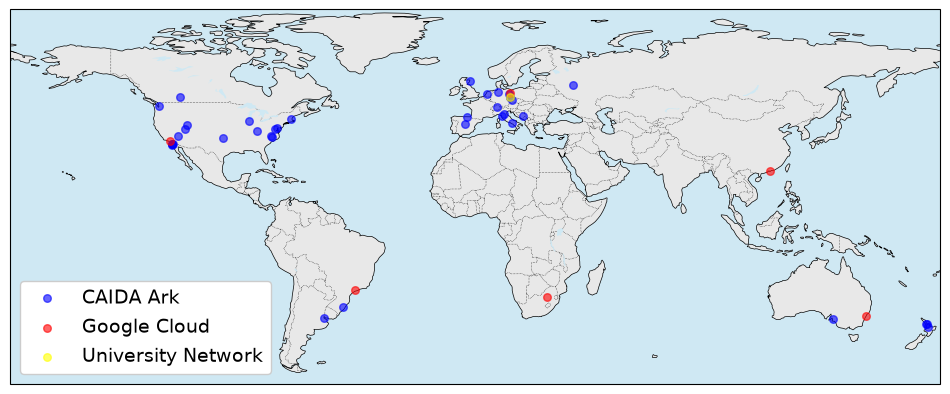

In [5]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.PlateCarree())


ax.add_feature(cfeature.LAND, facecolor="#e8e8e8")
ax.add_feature(cfeature.OCEAN, facecolor="#cfe8f3")
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linewidth=0.4, linestyle=":")
ax.add_feature(cfeature.LAKES, facecolor="#cfe8f3")
ax.set_extent([-180, 180, -60, 85], crs=ccrs.PlateCarree())

color_map = {"CAIDA Ark": "blue", "Google Cloud": "red", "University Network": "yellow"}

for kind, color in color_map.items():
    sub = df_all.filter(pl.col("kind") == kind)
    ax.scatter(
        sub["lon"].to_numpy(),
        sub["lat"].to_numpy(),
        transform=ccrs.PlateCarree(),
        s=30,
        c=color,
        alpha=0.6,
        label=kind,  # CHANGE 3: label for the legend
        zorder=2,
    )

ax.legend(loc="lower left", facecolor="white", framealpha=1, fontsize=14)
vh.save_plot(fig, "ark-map", config.FIGURES_DIR / "ark-map")
# plt.savefig("map.pdf", dpi=150, bbox_inches="tight")